# Axis 5 — Memory Hierarchy & Expert Placement (Mac / MLX)

**Question (team page).** How does placing experts across memory tiers affect end-to-end latency and throughput?

**Tiers.** Windows has three tiers (VRAM → RAM → disk). Apple Silicon has **two**: **unified memory** (where the GPU computes from) and **disk** (the SSD). So on the Mac the question becomes: *given a fixed unified-memory budget for experts, which experts should live there, and should that set be fixed or change over time?*

## Strategies compared at the same budget B (experts in unified memory)
| Strategy | Unified-memory tier | Changes over time? |
|---|---|---|
| **static** | the B − 64 experts used most in a *profiling* run, pinned for good, plus a 64-slot staging area (the minimum to compute any layer call) | almost not at all |
| **hybrid** | B/2 pinned hottest experts + B/2 LRU slots | half |
| **dynamic** | B LRU slots, nothing pinned | fully |

* Profiling uses a **different** set of prompts from the evaluation, so pinning is not tuned to the test.
* Pinned experts are loaded before the run (startup cost reported separately, not counted as misses).
* Everything that is not resident is read from disk on demand, page cache bypassed.

**Hypothesis, translated.** A hierarchy that keeps frequently reused experts in the fast tier and fetches only cold tails from disk beats a single uniform policy, and the right split minimises disk reads at a given budget.

**Runtime.** ≈ 45–60 min full; `MOE_SMOKE=1` a few minutes.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlx.core as mx

# Find the repo and import the shared module (experiments/moe_cache.py).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments' / 'moe_cache.py').exists())
sys.path.insert(0, str(ROOT / 'experiments'))
import moe_cache as mc                 # Mac only (MLX)
import results as rs, figures as fg    # any device: results file format + cross-device figures
for m in (mc, rs, fg):
    importlib.reload(m)

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-5-memory-tiering'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-5-memory-tiering') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

DEVICE = 'mac'                          # results file: <axis>/results/mac.json
AXIS = 'axis-5-memory-tiering'
TABLES = {}                             # every table this run produces, saved at the end

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(mc.system_info())

Full run | results -> experiments/axis-5-memory-tiering/results
{'chip': 'Apple M4', 'ram_GB': 17.2, 'macOS': '27.2', 'python': '3.14.8', 'mlx': '0.32.2'}


## Configuration

In [2]:
BUDGETS = [192, 384, 576]          # experts resident in unified memory (bank = B x 12.6 MB)
STAGING = 64                       # dynamic slots kept by the static strategy
HYBRID_PIN_FRACTION = 0.5
PROFILE_PER_DOMAIN = 2             # profiling prompts per kind (disjoint from evaluation; max 2+2)
EVAL_PER_DOMAIN = 2
MAX_NEW_TOKENS = 48
REPLAY_BUDGETS = [128, 192, 256, 384, 512, 576, 768]   # denser curve by exact replay

if SMOKE:
    BUDGETS, PROFILE_PER_DOMAIN, EVAL_PER_DOMAIN, MAX_NEW_TOKENS = [192], 1, 1, 6
    REPLAY_BUDGETS = [128, 192, 256]
print('budgets:', BUDGETS, '| strategies: static, hybrid, dynamic')
CONFIG = rs.config_from(globals())   # recorded in the results file

budgets: [192, 384, 576] | strategies: static, hybrid, dynamic


## Model and correctness gate

In [3]:
model, tokenizer, index = mc.load_model()
print(index.describe())
print(f'Non-expert weights resident: {mc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| MLX active memory: {mx.get_active_memory() / 1e9:.2f} GB')
# Measured ONCE, before any expert bank exists: free RAM read later in the run is unreliable.
SAFE_K = mc.max_safe_capacity(index)
print(f'Largest K that fits in the RAM free right now: {SAFE_K} (bank {SAFE_K * index.expert_bytes / 1e9:.1f} GB)')

# Correctness gate: one layer through the K-slot bank vs the stock mlx-lm layer
# (all 64 experts of that layer stacked). Must be bit-identical.
diff = mc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock mlx-lm: max |diff| = {diff}')

16 layers x 64 experts = 1024 logical experts | 12.58 MB each (F16) | full bank 12.9 GB on disk
Non-expert weights resident: 0.95 GB | MLX active memory: 0.95 GB
Largest K that fits in the RAM free right now: 414 (bank 5.2 GB)


Layer exactness vs stock mlx-lm: max |diff| = 0.0


## Profiling run: which experts are hot?

In [4]:
# Written for this axis: per kind of request, the first PROFILE_PER_DOMAIN prompts are used
# to find hot experts and the following EVAL_PER_DOMAIN are the held-out evaluation traffic.
prompt_file = rs.load_prompts(AXIS_DIR)   # axis-5-memory-tiering/prompts.json, shared by every device
PROMPTS = prompt_file['PROMPTS']
profile_reqs = mc.requests(PROMPTS, n_per_domain=PROFILE_PER_DOMAIN, order='interleave')
eval_reqs = mc.requests(PROMPTS, n_per_domain=EVAL_PER_DOMAIN, order='interleave', offset=PROFILE_PER_DOMAIN)
assert not {p['text'] for p in profile_reqs} & {p['text'] for p in eval_reqs}

cache = mc.ExpertCache(index, min(256, SAFE_K), 'LRU')   # profiling cache: outputs do not depend on K
_, rec = mc.run_workload(model, tokenizer, cache, profile_reqs, MAX_NEW_TOKENS, log=None)
cache.close(); mc.detach_cache(model)
prof = mc.events_frame(rec.events)
ranking = prof.groupby(['layer', 'eid']).size().sort_values(ascending=False)
hot = [tuple(map(int, k)) for k in ranking.index]
print(f'profiling: {len(profile_reqs)} requests, {len(prof):,} accesses, {len(hot)} distinct experts')
print('top-10 experts (layer, id):', hot[:10])
print('share of accesses covered by the top 128 / 256 / 512:',
      [f'{ranking.iloc[:n].sum() / ranking.sum():.0%}' for n in (128, 256, 512)])

profiling: 8 requests, 54,613 accesses, 1022 distinct experts
top-10 experts (layer, id): [(0, 6), (12, 43), (9, 5), (5, 0), (6, 18), (7, 17), (0, 41), (6, 5), (11, 27), (10, 16)]
share of accesses covered by the top 128 / 256 / 512: ['25%', '43%', '70%']


## Real runs on the evaluation requests

In [5]:
def make_strategy(name, B):
    if name == 'dynamic':
        return mc.make_policy('LRU', B), []
    n_pin = B - STAGING if name == 'static' else int(B * HYBRID_PIN_FRACTION)
    pins = hot[:n_pin]
    return mc.TieredPolicy(B, pins, 'LRU'), pins

timed = [b for b in BUDGETS if b <= SAFE_K]
assert timed, f'No budget fits in free RAM (largest safe K = {SAFE_K}). Close other apps and re-run.'
if len(timed) < len(BUDGETS):
    print(f'Not timed (bank would not fit): {[b for b in BUDGETS if b > SAFE_K]} -> see the replay curve below')
rows, traces = [], {}
for B in timed:
    for strat in ['static', 'hybrid', 'dynamic']:
        mc.free_memory(); mx.reset_peak_memory()
        pol, pins = make_strategy(strat, B)
        cache = mc.ExpertCache(index, B, pol)
        startup_ms = cache.preload(pins)
        t0 = time.perf_counter()
        df, rec = mc.run_workload(model, tokenizer, cache, eval_reqs, MAX_NEW_TOKENS, log=None)
        s = cache.summary()
        p2, _ = make_strategy(strat, B)
        hits = mc.replay(rec.events, p2)
        assert int(hits.sum()) == s['hits'], 'replay mismatch'
        dec_tok = (df.new_tokens - 1).sum()
        acc = mc.events_frame(rec.events)
        rows.append({'B': B, 'strategy': strat, 'pinned': len(pins), 'hit_rate': s['hit_rate'],
                     'decode_hit_rate': hits[(acc.phase == 'decode').to_numpy()].mean(),
                     'GB_loaded': s['GB_loaded'], 'io_s': s['io_ms'] / 1000,
                     'startup_s': startup_ms / 1000, 'startup_GB': len(pins) * index.expert_bytes / 1e9,
                     'decode_tok_s': dec_tok / df.decode_s.sum(), 'ttft_mean_s': df.ttft_s.mean(),
                     'wall_s': time.perf_counter() - t0, 'peak_GB': mx.get_peak_memory() / 1e9})
        traces[(B, strat)] = rec.events
        cache.close(); mc.detach_cache(model)
        r = rows[-1]
        print(f'B={B} {strat:8s}: hit {r["hit_rate"]:.1%} (decode {r["decode_hit_rate"]:.1%}) | '
              f'{r["GB_loaded"]:.1f} GB read in {r["io_s"]:.1f}s | {r["decode_tok_s"]:.2f} tok/s | '
              f'TTFT {r["ttft_mean_s"]:.2f}s | startup {r["startup_s"]:.1f}s')
res = pd.DataFrame(rows)
TABLES['runs'] = res
res.style.format(precision=2)

Not timed (bank would not fit): [576] -> see the replay curve below


B=192 static  : hit 23.0% (decode 24.2%) | 529.5 GB read in 126.1s | 2.89 tok/s | TTFT 2.72s | startup 0.6s


B=192 hybrid  : hit 25.4% (decode 27.4%) | 512.8 GB read in 120.9s | 3.03 tok/s | TTFT 2.86s | startup 0.5s


B=192 dynamic : hit 37.4% (decode 42.3%) | 430.2 GB read in 113.9s | 3.32 tok/s | TTFT 3.30s | startup 0.0s


B=384 static  : hit 49.2% (decode 51.2%) | 349.0 GB read in 87.2s | 4.02 tok/s | TTFT 2.51s | startup 2.4s


B=384 hybrid  : hit 60.3% (decode 65.3%) | 272.8 GB read in 75.5s | 4.79 tok/s | TTFT 2.80s | startup 1.0s


B=384 dynamic : hit 60.4% (decode 67.1%) | 272.6 GB read in 86.9s | 4.46 tok/s | TTFT 3.45s | startup 0.0s


,B,strategy,pinned,hit_rate,decode_hit_rate,GB_loaded,io_s,startup_s,startup_GB,decode_tok_s,ttft_mean_s,wall_s,peak_GB
0,192,static,128,0.23,0.24,529.49,126.05,0.55,1.61,2.89,2.72,151.90,3.41
1,192,hybrid,96,0.25,0.27,512.77,120.94,0.53,1.21,3.03,2.86,146.88,3.41
2,192,dynamic,0,0.37,0.42,430.16,113.90,0.00,0.00,3.32,3.30,139.89,3.41
3,384,static,320,0.49,0.51,349.04,87.21,2.35,4.03,4.02,2.51,113.72,5.83
4,384,hybrid,192,0.60,0.65,272.76,75.52,0.97,2.42,4.79,2.80,101.02,5.83
5,384,dynamic,0,0.60,0.67,272.63,86.92,0.00,0.00,4.46,3.45,111.99,5.83


## Denser budget curve by exact replay
The evaluation access stream is the same for every strategy (outputs do not depend on the cache), so each strategy can be replayed at more budgets — including ones too large to time on this machine. Replay was asserted equal to every real run above.

In [6]:
events = next(iter(traces.values()))
acc = mc.events_frame(events)
dec = (acc.phase == 'decode').to_numpy()
rep = []
for B in REPLAY_BUDGETS:
    for strat in ['static', 'hybrid', 'dynamic']:
        if strat == 'static' and B <= STAGING:
            continue
        pol, _ = make_strategy(strat, B)
        h = mc.replay(events, pol)
        rep.append({'B': B, 'strategy': strat, 'hit_rate': h.mean(), 'decode_hit_rate': h[dec].mean(),
                    'GB_read': (~h).sum() * index.expert_bytes / 1e9})
rep = pd.DataFrame(rep)
TABLES['replay'] = rep
rep.pivot(index='B', columns='strategy', values='hit_rate').style.format('{:.1%}').highlight_max(axis=1, color='#c6efce')

strategy,dynamic,hybrid,static
B,,,
128,35.0%,13.4%,13.4%
192,37.4%,25.4%,23.0%
256,46.6%,46.6%,32.1%
384,60.4%,60.3%,49.2%
512,71.5%,71.4%,67.0%
576,76.2%,76.7%,74.0%
768,88.4%,89.2%,89.9%


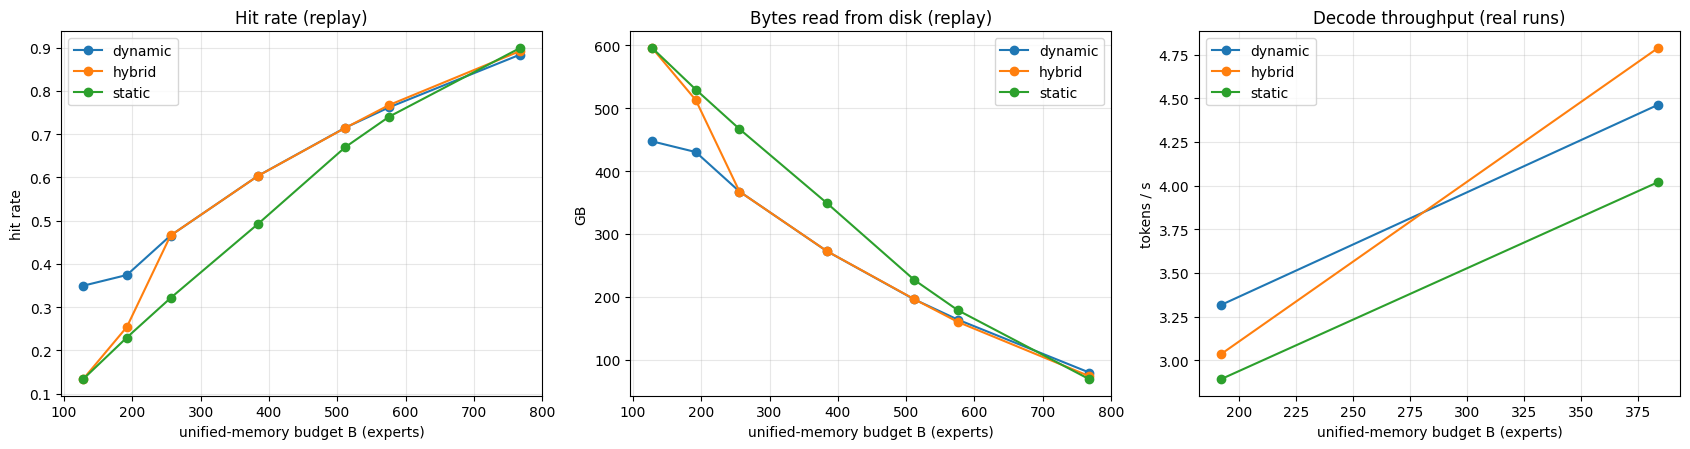

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for strat, d in rep.groupby('strategy'):
    axes[0].plot(d.B, d.hit_rate, '-o', label=strat)
    axes[1].plot(d.B, d.GB_read, '-o', label=strat)
for strat, d in res.groupby('strategy'):
    axes[2].plot(d.B, d.decode_tok_s, '-o', label=strat)
axes[0].set_title('Hit rate (replay)'); axes[0].set_ylabel('hit rate')
axes[1].set_title('Bytes read from disk (replay)'); axes[1].set_ylabel('GB')
axes[2].set_title('Decode throughput (real runs)'); axes[2].set_ylabel('tokens / s')
for ax in axes:
    ax.set_xlabel('unified-memory budget B (experts)'); ax.legend()
fig.tight_layout(); plt.show()

## Hypothesis check (descriptive)

In [8]:
for B, d in rep.groupby('B'):
    d = d.set_index('strategy').hit_rate
    print(f'B={B:4d}: best = {d.idxmax():8s} ({d.max():.1%}); ' + ', '.join(f'{k} {v:.1%}' for k, v in d.items()))
for B, d in res.groupby('B'):
    d = d.set_index('strategy')
    print(f'real B={B}: fastest decode = {d.decode_tok_s.idxmax()} ({d.decode_tok_s.max():.2f} tok/s); '
          f'static pays {d.loc["static", "startup_s"]:.1f}s of startup loading '
          f'({d.loc["static", "startup_GB"]:.1f} GB)')
print('\nA tiered layout "wins" here only if pinning what was hot in profiling beats pure recency on new prompts.')

B= 128: best = dynamic  (35.0%); static 13.4%, hybrid 13.4%, dynamic 35.0%
B= 192: best = dynamic  (37.4%); static 23.0%, hybrid 25.4%, dynamic 37.4%
B= 256: best = hybrid   (46.6%); static 32.1%, hybrid 46.6%, dynamic 46.6%
B= 384: best = dynamic  (60.4%); static 49.2%, hybrid 60.3%, dynamic 60.4%
B= 512: best = dynamic  (71.5%); static 67.0%, hybrid 71.4%, dynamic 71.5%
B= 576: best = hybrid   (76.7%); static 74.0%, hybrid 76.7%, dynamic 76.2%
B= 768: best = static   (89.9%); static 89.9%, hybrid 89.2%, dynamic 88.4%
real B=192: fastest decode = dynamic (3.32 tok/s); static pays 0.6s of startup loading (1.6 GB)
real B=384: fastest decode = hybrid (4.79 tok/s); static pays 2.4s of startup loading (4.0 GB)

A tiered layout "wins" here only if pinning what was hot in profiling beats pure recency on new prompts.


## Save results
Every table above goes into **one file for this device**: `results/mac.json`, with the configuration, prompts and machine it ran on.
The Windows notebooks write `windows-igpu.json` / `windows-dgpu.json` next to it in the same format (see `experiments/README.md`).

In [ ]:
CONFIG['SAFE_K'] = globals().get('SAFE_K')
path = rs.save(RESULTS, AXIS, DEVICE, TABLES, config=CONFIG, prompts=rs.load_prompts(AXIS_DIR),
               system=mc.system_info())
print('Saved', path.relative_to(ROOT), '| tables:', {k: len(v) for k, v in TABLES.items()})

## Cross-device figures
The report figures, drawn from every device's results file in this folder (colour = device). Only shown here;
`python experiments/figures.py` writes them to `figures/` once all devices have results.

In [ ]:
figs = fg.make(AXIS, RESULTS)